In [10]:
import pandas as pd


terror_dataset = pd.read_csv("Global Terrorism Dataset/final.csv")
afg_data = terror_dataset.loc[(terror_dataset["year"]==2010) & (terror_dataset["country"]=="afghanistan"), "nkill"]

iqr = afg_data.quantile(0.75) - afg_data.quantile(.25)

diff = (afg_data - afg_data.median()).abs()
mad = diff.median()

mad


1.0

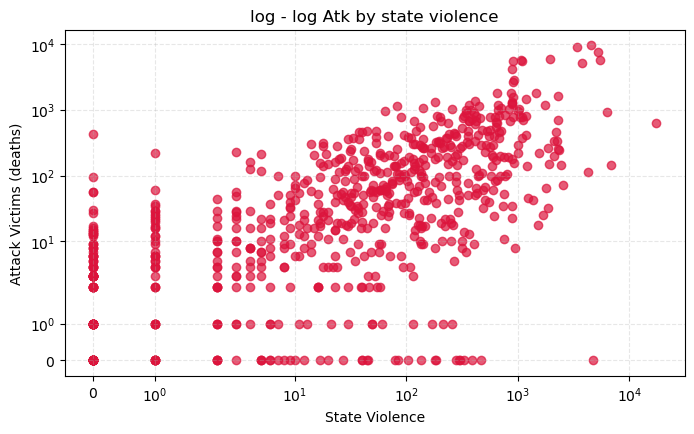

In [13]:
import matplotlib.pyplot as plt
afg_time_series = terror_dataset

atk_per_yr = afg_time_series.groupby(["year", "country"]).sum().nkill.sort_index()
killings_per_yr = afg_time_series.groupby(["year", "country"]).deaths_civilians.mean().sort_index()

plt.figure(figsize=(8,4.5))
plt.scatter(y=atk_per_yr.values, x=killings_per_yr.values, color="crimson", alpha=0.7)
plt.title("log - log Atk by state violence")
plt.xlabel("State Violence")
plt.ylabel("Attack Victims (deaths)")
plt.grid(True, linestyle="--", alpha=0.3)
plt.xscale("symlog")
plt.yscale("symlog")
plt.show()


In [12]:
terror_dataset.head()

,year,country,date,region_txt,provstate,city,nkill,nwound,deaths_civilians,value
0,1990,nicaragua,1990-01-01,Central America & Caribbean,North Caribbean Coast Autonomous Region,puerto cabezas district,2.0,0.0,2.0,0.515
1,1990,colombia,1990-01-02,South America,Cundinamarca,unknown,0.0,0.0,172.0,0.623
2,1990,peru,1990-01-02,South America,Unknown,amnaija,0.0,2.0,142.0,0.625
3,1990,united kingdom,1990-01-02,Western Europe,Northern Ireland,belfast,1.0,0.0,10.0,0.812
4,1990,peru,1990-01-02,South America,Ancash,huaylas,0.0,0.0,142.0,0.625


In [5]:
import pandas as pd
terror_dataset = pd.read_csv("Global Terrorism Dataset/final.csv")
nkill = terror_dataset["nkill"].dropna()
nkill_average = nkill.mean()

stdev = nkill.std(ddof=0)
flawed_skewness = ((nkill - nkill_average) **3).sum() / (len(nkill)*stdev**3)
accurate_skewness = ((len(nkill)*(len(nkill) -1))**(1/2)/(len(nkill)-2)) * flawed_skewness
accurate_skewness
panda_skewness = nkill.skew()
panda_skewness, accurate_skewness

(np.float64(48.579894694435616), np.float64(48.57989469440139))